In [1]:
from keras import Sequential
import os
import sys
import hls4ml
import numpy as np
from keras.layers import (
    BatchNormalization,
    Flatten,
    Input,
)
from keras.optimizers import Adam
from qkeras.quantizers import quantized_bits, quantized_relu
from keras.layers import Activation
from qkeras import (
    QActivation,
    QConv2D,
    QDense,
)

from config import (
    DATASET_PATH,
    NUM_CLASSES,
    TEST_SIZE,
    RANDOM_SEED,
    DATASET_TRANSPOSE,
    VALIDATION_SPLIT,
    INPUT_SHAPE,

)
from sklearn.metrics import accuracy_score

import matplotlib.pyplot as plt
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from quantizers_configurations import build_quantizers

from scipy.io import loadmat

sys.path.append('..')
import plotting

2026-08-25 10:11:58.424249: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-08-25 10:11:58.425283: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-08-25 10:11:58.443952: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-08-25 10:11:58.444588: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-08-25 10:11:58.836667: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:3

In [ ]:
data = loadmat("data/sat-6-full.mat")

images = data["train_x"].astype(np.int8)

labels = data["train_y"]
images = images.transpose((3, 0, 1, 2))

labels = labels.argmax(axis=0)
labels = to_categorical(labels, 6)

X_train_val, X_test, y_train_val, y_test = train_test_split(
    images,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels.argmax(axis=1),
)

X_train, X_validation, y_train, y_validation = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.20,
    random_state=42,
    stratify=y_train_val.argmax(axis=1),
)

label_list = np.array([], dtype=np.object_)
for key, value in data.items():
    if key == 'annotations':
        for k in value:
            label_list = np.append(label_list, k[1])

label_list

array(['building', 'barren land', 'trees', 'grassland', 'road', 'water'],
      dtype=object)

In [3]:
def build_t1(bits: int) -> Sequential:
    q = build_quantizers(bits)

    model = Sequential(name="t1_int8")
    #model.add(Input(shape=INPUT_SHAPE, name="network_input"))

    model.add(
        QConv2D(
            input_shape=INPUT_SHAPE,
            filters=16,
            kernel_size=(3, 3),
            strides=(2, 2),
            padding="same",
            kernel_quantizer=q.weights,
            bias_quantizer=q.weights,
            name="conv2d_1",
        )
    )
    #model.add(BatchNormalization(name="batch_normalization_1"))
    model.add(QActivation(q.activation, name="activation_1"))

    model.add(
        QConv2D(
            filters=32,
            kernel_size=(1, 1),
            padding="valid",
            kernel_quantizer=q.weights,
            bias_quantizer=q.weights,
            name="conv2d_2",
        )
    )
    #model.add(BatchNormalization(name="batch_normalization_2"))
    model.add(QActivation(q.activation, name="activation_2"))

    model.add(Flatten(name="flatten"))

    model.add(
        QDense(
            64,
            kernel_quantizer=q.weights,
            bias_quantizer=q.weights,
            name="dense_1",
        )
    )
    #model.add(BatchNormalization(name="batch_normalization_3"))
    model.add(QActivation(q.activation, name="activation_3"))

    model.add(
        QDense(
            NUM_CLASSES,
            kernel_quantizer=q.weights,
            bias_quantizer=q.weights,
            name="dense_output",
        )
    )
    model.add(Activation(activation='softmax', name='softmax'))

    return model

model = build_t1(bits=8)


/home/fauri/Documentos/hls4ml/.venv_hls4ml_t/lib/python3.10/site-packages/keras/src/initializers/initializers.py:120: UserWarning: The initializer HeNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


In [4]:
model.compile(optimizer=Adam(learning_rate=1e-4), loss='categorical_crossentropy', metrics=['accuracy'])
model.fit(
    X_train_val,
    y_train_val,
    batch_size=512,
    epochs=30,
    validation_split=0.25,
    shuffle=True,
)
os.makedirs('test_models/', exist_ok=True)
model.save('test_models/qmodel.h5')

Epoch 1/30
380/380 [==============================] - 5s 12ms/step - loss: 2548.2771 - accuracy: 0.5087 - val_loss: 1847.5984 - val_accuracy: 0.6054
Epoch 2/30
380/380 [==============================] - 4s 11ms/step - loss: 1738.7871 - accuracy: 0.6198 - val_loss: 1500.0835 - val_accuracy: 0.6716
Epoch 3/30
380/380 [==============================] - 4s 11ms/step - loss: 1375.1602 - accuracy: 0.6799 - val_loss: 1336.0714 - val_accuracy: 0.6599
Epoch 4/30
380/380 [==============================] - 4s 11ms/step - loss: 1227.0967 - accuracy: 0.7076 - val_loss: 1645.1868 - val_accuracy: 0.5951
Epoch 5/30
380/380 [==============================] - 4s 11ms/step - loss: 1345.0280 - accuracy: 0.6844 - val_loss: 1739.2046 - val_accuracy: 0.5865
Epoch 6/30
380/380 [==============================] - 4s 10ms/step - loss: 1516.2563 - accuracy: 0.6534 - val_loss: 1388.6173 - val_accuracy: 0.6637
Epoch 7/30
380/380 [==============================] - 4s 10ms/step - loss: 1556.6395 - accuracy: 0.6424 - 

/home/fauri/Documentos/hls4ml/.venv_hls4ml_t/lib/python3.10/site-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [5]:
config = hls4ml.utils.config_from_keras_model(model, granularity='name', backend='Vitis')
#config['LayerName']['softmax']['exp_table_t'] = 'ap_fixed<18,8>'
#config['LayerName']['softmax']['inv_table_t'] = 'ap_fixed<18,4>'
hls_model = hls4ml.converters.convert_from_keras_model(
    model,
    hls_config=config,
    backend='Vitis',
    output_dir='../hls4ml_prjs/hls4ml_prj_qkeras_part2',
    part='xc7z020clg400-1',
)
hls_model.compile()

y_qkeras = model.predict(np.ascontiguousarray(X_test).astype(np.float32))
y_hls = hls_model.predict(np.ascontiguousarray(X_test).astype(np.float32))

2025/2025 [==============================] - 2s 937us/step


In [15]:
config

{'Model': {'Precision': {'default': 'fixed<16,6>'},
  'ReuseFactor': 1,
  'Strategy': 'Latency',
  'BramFactor': 1000000000,
  'TraceOutput': False,
  'BitExact': None},
 'LayerName': {'conv2d_1_input': {'Trace': False,
   'Precision': {'result': 'auto'}},
  'conv2d_1': {'Trace': False,
   'Precision': {'result': 'auto',
    'weight': 'fixed<8,8,TRN,WRAP,0>',
    'bias': 'fixed<8,8,TRN,WRAP,0>',
    'accum': 'auto'},
   'ReuseFactor': 1,
   'ParallelizationFactor': 1,
   'ConvImplementation': 'LineBuffer'},
  'conv2d_1_linear': {'Trace': False,
   'Precision': {'result': 'auto', 'table': 'fixed<18,8,TRN,WRAP,0>'},
   'ReuseFactor': 1,
   'TableSize': 1024},
  'activation_1': {'Trace': False,
   'Precision': {'result': 'int<8>', 'table': 'fixed<18,8,TRN,WRAP,0>'},
   'ReuseFactor': 1,
   'TableSize': 1024},
  'conv2d_2': {'Trace': False,
   'Precision': {'result': 'auto',
    'weight': 'fixed<8,8,TRN,WRAP,0>',
    'bias': 'fixed<8,8,TRN,WRAP,0>',
    'accum': 'auto'},
   'ReuseFactor': 

In [14]:
y_hls[1], np.argmax(y_hls, axis=1)

(array([0.16699219, 0.16699219, 0.16699219, 0.16699219, 0.16699219,
        0.16699219], dtype=float32),
 array([0, 0, 0, ..., 0, 0, 0]))

In [13]:
y_test[0], np.argmax(y_test, axis=1)

(array([0., 0., 0., 0., 0., 1.], dtype=float32),
 array([5, 1, 2, ..., 2, 5, 2]))

KERAS Accuracy: 0.6134413580246914
hls4ml Accuracy: 0.046064814814814815


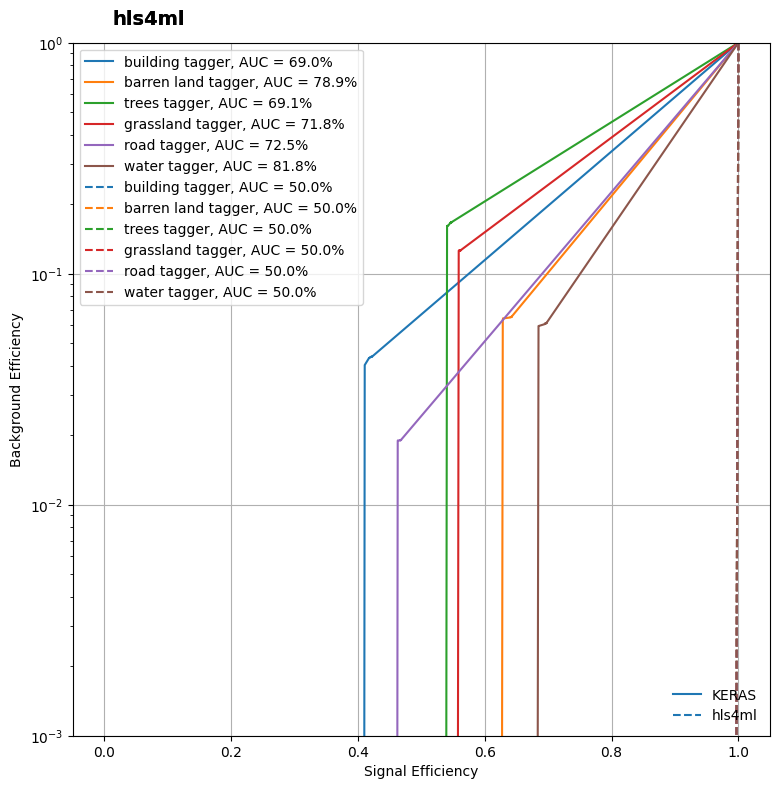

In [7]:

print("{} Accuracy: {}".format('KERAS', accuracy_score(np.argmax(y_test, axis=1), np.argmax(y_qkeras, axis=1))))
print("hls4ml Accuracy: {}".format(accuracy_score(np.argmax(y_test, axis=1), np.argmax(y_hls, axis=1))))

fig, ax = plt.subplots(figsize=(9, 9))
_ = plotting.makeRoc(y_test, y_qkeras, list(label_list))
plt.gca().set_prop_cycle(None)
_ = plotting.makeRoc(y_test, y_hls, list(label_list), linestyle='--')


from matplotlib.lines import Line2D
from matplotlib.legend import Legend

lines = [Line2D([0], [0], ls='-'), Line2D([0], [0], ls='--')]
leg = Legend(ax, lines, labels=['KERAS', 'hls4ml'], loc='lower right', frameon=False)
ax.add_artist(leg)